# Graph Neural Networks from Scratch — Tutorial 5: Message Passing Neural Networks

### From using graph convolution layers to building our own message-passing layer

*📺 Video on YouTube | 🐍 Python · PyTorch · PyTorch Geometric | Intermediate*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

In Tutorial 1, we learned how graphs represent connected data through nodes, edges, adjacency matrices, and node features.

In Tutorial 2, we implemented a **Graph Convolutional Network (GCN) forward pass from scratch using NumPy**. We explored self-loops, degree matrices, graph normalization, and neighbourhood aggregation.

In Tutorial 3, we introduced **PyTorch** and transformed our GCN into a trainable neural network. We explored learnable parameters, automatic differentiation, backpropagation, and node classification.

In Tutorial 4, we introduced **PyTorch Geometric (PyG)** and used the **Cora citation network** to build a practical GCN. We learned how PyG stores graphs with `edge_index` and `Data`, and how to train and evaluate a GNN on a real-world dataset.

So far, we have used graph convolution layers to propagate information between connected nodes. But what actually happens inside these layers?

In this tutorial, we will explore the fundamental mechanism behind many graph neural networks: **message passing**.

We will break the process into three essential operations: message, aggregate, and update. Starting with a simple implementation using PyTorch, we will then build a custom message-passing layer using PyG's `MessagePassing` class.

The goal is to understand the general framework behind GNNs rather than treating each architecture as a separate black box.
| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | learnable parameters, backpropagation, node classification | ✅ |
| 4 | PyTorch Geometric and the Cora Dataset | PyG, real-world graph data, practical GCN implementation | ✅ |
| **5** | **Message Passing Neural Networks** | **message, aggregate, update, custom GNN layers** | **📍 You are here** |
| 6 | Graph Attention Networks (GAT) | attention-based neighbourhood aggregation | Planned |
| 7 | GraphSAGE and Advanced Aggregation | scalable neighbourhood learning | Planned |
| 8 | Graph-Level Learning | graph classification and regression | Planned |
| 9 | GNNs for Mesh-Based Systems | mesh connectivity, geometric features, scientific data | Planned |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to progress from understanding graph representations and implementing GNNs from scratch to using practical tools for learning from complex connected systems, including computational meshes and physical systems.

---

In this tutorial, we will explore the essential components of message-passing neural networks:

- The three operations: message, aggregate, and update.
- How edge direction in `edge_index` controls information flow.
- Implementing neighbourhood aggregation with plain PyTorch (`index_add_`).
- Building a trainable GraphSAGE-style layer from scratch.
- Understanding PyG's `MessagePassing` class, `propagate()`, `x_i`, and `x_j`.
- Verifying that our PyG layer matches the manual implementation.
- Training our custom layer on Cora with the Tutorial 4 workflow.
- Receptive fields, oversmoothing, and how `GCNConv` fits into the same framework.

We will begin with a four-node graph to see exactly how information moves. Then, we will scale the same idea up to Cora.

## The learning process

Our workflow in this tutorial will follow this sequence:

```text
        Small Example Graph
                |
                v
     Message → Aggregate → Update
        (plain PyTorch)
                |
                v
    Trainable GraphSAGE-style Layer
                |
                v
     PyG MessagePassing Layer
     (verify against manual code)
                |
                v
           Cora Dataset
                |
                v
     Train → Validate → Test
                |
                v
   Inspect Predictions + Experiments
```

Unlike Tutorial 4, where `GCNConv` handled the graph operation internally, here **we write the layer ourselves**. The training loop, masks, and evaluation stay the same as in Tutorial 4, only the layer changes.

> **New to message passing?** Don't worry. We will build every piece step by step on a graph small enough to check by hand. Familiarity with PyTorch, `edge_index`, and the Cora workflow from Tutorial 4 will be helpful.
>
> If you're interested in scientific machine learning, CFD, or computational mechanics, pay attention to the message function. In an unstructured mesh, neighbouring cells exchange information through shared faces. A message-passing layer is a natural way to learn such local interactions, although conservation and geometric constraints must be added explicitly.

**Let's now open the GNN black box and see how nodes exchange, combine, and update information.**

## 1. Why message passing?

In Tutorial 2, we wrote a GCN layer as one matrix equation:

$$
H^{(l+1)}=\sigma\left(\hat D^{-1/2}\hat A\hat D^{-1/2}H^{(l)}W^{(l)}\right)
$$

This is compact, but it hides *what each node actually does*. It also ties us to one specific choice of neighbour weighting.

Message passing describes the same computation **from the point of view of a single node**:

1. **Message:** each neighbour sends a vector to the node.
2. **Aggregate:** the node combines all incoming messages into one vector.
3. **Update:** the node combines this aggregate with its own representation.

Changing any of these three steps gives a different GNN. GCN, GraphSAGE, and GAT are all special cases.

## 2. Setup

We use the same environment as Tutorial 4.

```bash
pip install torch-geometric
```

In [2]:
import sys
import subprocess

import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch:", torch.__version__)

try:
    import torch_geometric
except ImportError:
    print("PyTorch Geometric is not installed. Installing it now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch-geometric"])
    import torch_geometric
    print("Installation complete.")

print("PyG:", torch_geometric.__version__)

torch.manual_seed(7)

PyTorch: 2.11.0+cu130
PyG: 2.8.1


# Part I — Message passing on a small graph

## 3. The three operations

For a directed edge from node $j$ (source) to node $i$ (destination), a message is computed as:

$$
\mathbf m_{j\rightarrow i}^{(k)} = \phi^{(k)}\left(\mathbf h_i^{(k-1)},\ \mathbf h_j^{(k-1)},\ \mathbf e_{ji}\right)
$$

The messages arriving at node $i$ are aggregated:

$$
\mathbf m_i^{(k)} = \bigoplus_{j\in\mathcal N(i)} \mathbf m_{j\rightarrow i}^{(k)}
$$

The node representation is then updated:

$$
\mathbf h_i^{(k)} = \gamma^{(k)}\left(\mathbf h_i^{(k-1)},\ \mathbf m_i^{(k)}\right)
$$

| Symbol | Meaning |
|---|---|
| $\mathbf h_i$ | representation (feature vector) of node $i$ |
| $\mathbf e_{ji}$ | optional edge feature |
| $\phi$ | message function |
| $\bigoplus$ | aggregation: sum, mean, max, … |
| $\gamma$ | update function |

The aggregation must be **permutation-invariant**: the result cannot depend on the order in which neighbours are listed, because a graph has no natural neighbour order.

## 4. Our example graph

Consider this undirected graph with four nodes:

```text
    0 ------ 1
     \      /
      \    /
        2 ------ 3
```

Connections: 0–1, 0–2, 1–2, and 2–3. As in Tutorial 4, each undirected connection is stored as two directed edges. A column `[j, i]` in `edge_index` means **information travels from `j` to `i`**.

In [3]:
# Undirected edges: 0--1, 0--2, 1--2, 2--3
edge_index = torch.tensor([
    [0, 1, 0, 2, 1, 2, 2, 3],  # source nodes (j)
    [1, 0, 2, 0, 2, 1, 3, 2]   # destination nodes (i)
], dtype=torch.long)

x = torch.tensor([
    [1.0, 0.0],   # node 0
    [0.0, 1.0],   # node 1
    [1.0, 1.0],   # node 2
    [2.0, 0.0]    # node 3
])

print("Node features:", x.shape)
print("Edge index:", edge_index.shape)
for src, dst in edge_index.t().tolist():
    print(f"{src} -> {dst}")

Node features: torch.Size([4, 2])
Edge index: torch.Size([2, 8])
0 -> 1
1 -> 0
0 -> 2
2 -> 0
1 -> 2
2 -> 1
2 -> 3
3 -> 2


A node's neighbours are the **sources** of the edges that point *into* it. Let's list them.

In [4]:
neighbors = {i: [] for i in range(x.size(0))}
for src, dst in edge_index.t().tolist():
    neighbors[dst].append(src)

for node, nbrs in neighbors.items():
    print(f"Node {node}: receives messages from {nbrs}")

Node 0: receives messages from [1, 2]
Node 1: receives messages from [0, 2]
Node 2: receives messages from [0, 1, 3]
Node 3: receives messages from [2]


Node 2 has three neighbours, while node 3 has only one. This difference in **degree** will matter when we choose an aggregation.

## 🧪 Hands-on Exercise 1

Add an undirected edge between nodes 0 and 3 (both `0 → 3` and `3 → 0`). Rebuild the neighbour list.

Before running, predict: which nodes gain a neighbour? Which nodes' aggregates will change?

In [4]:
# TODO: add the edges 0 -> 3 and 3 -> 0, then rebuild the neighbour list.

# edge_index_ex1 = torch.cat([edge_index, torch.tensor([[0, 3], [3, 0]])], dim=1)
# neighbors_ex1 = {i: [] for i in range(x.size(0))}
# for src, dst in edge_index_ex1.t().tolist():
#     neighbors_ex1[dst].append(src)
# print(neighbors_ex1)

# Part II — Message and aggregation with plain PyTorch

## 5. The simplest message-passing step

We start with the simplest possible choices:

- **Message:** each source node sends its features unchanged: $\mathbf m_{j\rightarrow i}=\mathbf x_j$
- **Aggregate:** take the mean of incoming messages:

$$
\mathbf m_i=\frac{1}{|\mathcal N(i)|}\sum_{j\in\mathcal N(i)}\mathbf x_j
$$

- **Update:** add the node's own features: $\mathbf h_i'=\mathbf x_i+\mathbf m_i$

There are no learnable parameters yet. We only want to see information move.

In [5]:
def mean_aggregate(x, edge_index):
    """Mean of source-node features for each destination node."""
    src, dst = edge_index
    num_nodes = x.size(0)

    # 1. Message: one feature vector per edge
    messages = x[src]                      # shape [E, F]

    # 2. Aggregate: sum messages into destination rows, then divide by count
    aggregated = torch.zeros_like(x)
    aggregated.index_add_(0, dst, messages)

    counts = torch.zeros(num_nodes, 1, dtype=x.dtype, device=x.device)
    counts.index_add_(0, dst, torch.ones(dst.numel(), 1, dtype=x.dtype, device=x.device))

    return aggregated / counts.clamp(min=1)

neighbor_mean = mean_aggregate(x, edge_index)

# 3. Update
updated = x + neighbor_mean

print("Original features:\n", x)
print("\nMean neighbour features:\n", neighbor_mean)
print("\nUpdated features:\n", updated)

Original features:
 tensor([[1., 0.],
        [0., 1.],
        [1., 1.],
        [2., 0.]])

Mean neighbour features:
 tensor([[0.5000, 1.0000],
        [1.0000, 0.5000],
        [1.0000, 0.3333],
        [1.0000, 1.0000]])

Updated features:
 tensor([[1.5000, 1.0000],
        [1.0000, 1.5000],
        [2.0000, 1.3333],
        [3.0000, 1.0000]])


Check node 2 by hand. Its neighbours are 0, 1, and 3:

$$
\mathbf m_2=\frac{1}{3}\left([1,0]+[0,1]+[2,0]\right)=[1,\ 0.333]
$$

This matches the printed output.

## 6. Understanding `index_add_`

`index_add_` is the key operation behind sparse message passing:

```text
messages (one row per edge)        dst        aggregated (one row per node)
  edge 0: x[0]  ─────────────────▶  1   ─┐
  edge 1: x[1]  ─────────────────▶  0    │     row 0 ← x[1] + x[2]
  edge 2: x[0]  ─────────────────▶  2    ├──▶  row 1 ← x[0] + x[2]
  ...                               ...  │     row 2 ← x[0] + x[1] + x[3]
  edge 7: x[3]  ─────────────────▶  2   ─┘     row 3 ← x[2]
```

Each message is added to the row of its destination node. We never build the $N\times N$ adjacency matrix, the same reason PyG uses `edge_index` in Tutorial 4.

## 🧪 Hands-on Exercise 2 — Sum aggregation

Implement `sum_aggregate` by removing the division by `counts`. Compare nodes 2 and 3.

1. Which aggregation is more sensitive to node degree?
2. Which aggregation normalises by the number of neighbours?
3. Can mean aggregation tell a node with 1 neighbour `[1, 1]` apart from a node with 3 identical neighbours `[1, 1]`?

In [6]:
# TODO: implement sum aggregation.

def sum_aggregate(x, edge_index):
    src, dst = edge_index
    # messages = ...
    # aggregated = torch.zeros_like(x)
    # aggregated.index_add_(...)
    # return aggregated
    pass

# print(sum_aggregate(x, edge_index))

# Part III — A trainable message-passing layer

## 7. A GraphSAGE-style update

Our update $\mathbf h_i'=\mathbf x_i+\mathbf m_i$ has nothing to learn. A simple trainable choice is to **concatenate** the node's own features with the aggregated neighbour features and apply a linear layer:

$$
\mathbf h_i'=W\left[\ \mathbf h_i\ \Vert\ \operatorname{mean}_{j\in\mathcal N(i)}\mathbf h_j\ \right]+\mathbf b
$$

- $\Vert$ means concatenation, so the input to $W$ has size $2F$.
- $W$ and $\mathbf b$ are learnable.
- The activation $\sigma$ (ReLU) is applied in the model, between layers — exactly as in our `GCN` class from Tutorial 4.

Keeping $\mathbf h_i$ separate from the neighbour mean lets the model learn *how much* to trust the node itself versus its neighbourhood.

In [7]:
class MeanSAGELayer(nn.Module):
    """GraphSAGE-style layer written with plain PyTorch."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.linear = nn.Linear(2 * in_channels, out_channels)

    def forward(self, x, edge_index):
        neighbor_mean = mean_aggregate(x, edge_index)        # message + aggregate
        combined = torch.cat([x, neighbor_mean], dim=1)       # [N, 2F]
        return self.linear(combined)                          # update

layer = MeanSAGELayer(in_channels=2, out_channels=4)
out = layer(x, edge_index)

print(layer)
print("Input shape:", x.shape)
print("Output shape:", out.shape)
print(out)

MeanSAGELayer(
  (linear): Linear(in_features=4, out_features=4, bias=True)
)
Input shape: torch.Size([4, 2])
Output shape: torch.Size([4, 4])
tensor([[ 0.5951,  0.0608,  0.4895,  0.4030],
        [ 0.1565,  0.2587, -0.0706,  0.2377],
        [ 0.5069,  0.2582,  0.1660,  0.2878],
        [ 1.1065,  0.2716,  0.9328,  0.6515]], grad_fn=<AddmmBackward0>)


The layer maps each node from 2 features to 4. Because the output has a `grad_fn`, it can be trained with backpropagation, just like the GCN in Tutorial 3.

## 8. Count the learnable parameters

The linear layer has a weight matrix of shape $[\text{out},\ 2\cdot\text{in}]$ and a bias of shape $[\text{out}]$:

$$
4 \times (2\cdot 2) + 4 = 20
$$

In [8]:
num_params = sum(p.numel() for p in layer.parameters())
print("Learnable parameters:", num_params)

Learnable parameters: 20


# Part IV — Message passing with PyG

## 9. The `MessagePassing` base class

Writing `index_add_` by hand works, but it becomes repetitive. PyG provides a base class, `MessagePassing`, that handles the bookkeeping. We only define the parts that make our layer unique:

| What we write | What it does |
|---|---|
| `aggr="mean"` in `__init__` | chooses the aggregation |
| `message(self, x_j)` | computes one message per edge |
| `forward()` calling `self.propagate(edge_index, x=x)` | runs message → aggregate |
| code after `propagate()` | the update step |

```text
propagate(edge_index, x=x)
        |
        v
   message(x_j)        ← one row per edge
        |
        v
   aggregate (mean)    ← one row per node
        |
        v
   returned to forward() → update
```

With `flow="source_to_target"` (the default), messages travel from `edge_index[0]` to `edge_index[1]` — the same convention we have used throughout.

In [9]:
from torch_geometric.nn import MessagePassing

class PyGMeanSAGEConv(MessagePassing):
    """The same GraphSAGE-style layer, written with PyG's MessagePassing."""

    def __init__(self, in_channels, out_channels):
        super().__init__(aggr="mean", flow="source_to_target")
        self.linear = nn.Linear(2 * in_channels, out_channels)

    def forward(self, x, edge_index):
        neighbor_mean = self.propagate(edge_index, x=x)      # message + aggregate
        combined = torch.cat([x, neighbor_mean], dim=1)
        return self.linear(combined)                          # update

    def message(self, x_j):
        # x_j: features of the source node of each edge, shape [E, F]
        return x_j

    def __repr__(self):
        return f"{self.__class__.__name__}({self.linear.in_features // 2}, {self.linear.out_features})"

pyg_layer = PyGMeanSAGEConv(2, 4)
print(pyg_layer)
print(pyg_layer(x, edge_index).shape)

PyGMeanSAGEConv(2, 4)
torch.Size([4, 4])


## 10. What do `x_i` and `x_j` mean?

Inside `message()`, PyG lets us request node features **per edge** using a naming convention:

- `x_j` — features of the **source** node (the neighbour sending the message)
- `x_i` — features of the **destination** node (the node receiving it)

PyG builds these automatically from the `x=x` argument passed to `propagate()`. For example, `message(self, x_i, x_j)` returning `x_j - x_i` would send the *difference* between neighbour and node, a common choice for physical and mesh data.

## 11. Verify PyG against our manual implementation

A good habit: whenever we rewrite something with a library, check it against the version we understand. We build a layer that only performs message + aggregate.

In [10]:
class AggregateOnly(MessagePassing):
    def __init__(self, aggregation="mean"):
        super().__init__(aggr=aggregation, flow="source_to_target")

    def forward(self, x, edge_index):
        return self.propagate(edge_index, x=x)

    def message(self, x_j):
        return x_j

manual_mean = mean_aggregate(x, edge_index)
pyg_mean = AggregateOnly("mean")(x, edge_index)

print("Manual mean:\n", manual_mean)
print("\nPyG mean:\n", pyg_mean)
print("\nMaximum absolute difference:", (manual_mean - pyg_mean).abs().max().item())

Manual mean:
 tensor([[0.5000, 1.0000],
        [1.0000, 0.5000],
        [1.0000, 0.3333],
        [1.0000, 1.0000]])

PyG mean:
 tensor([[0.5000, 1.0000],
        [1.0000, 0.5000],
        [1.0000, 0.3333],
        [1.0000, 1.0000]])

Maximum absolute difference: 0.0


The difference is zero. `propagate()` is doing exactly what we wrote with `index_add_`.

We can also confirm the full trainable layer: copy the weights of `MeanSAGELayer` into `PyGMeanSAGEConv` and compare outputs.

In [11]:
pyg_layer.linear.load_state_dict(layer.linear.state_dict())

with torch.no_grad():
    diff = (layer(x, edge_index) - pyg_layer(x, edge_index)).abs().max().item()

print("Max difference between plain-PyTorch and PyG layer:", diff)

Max difference between plain-PyTorch and PyG layer: 0.0


## 🧪 Hands-on Exercise 3 — Aggregation choices

1. Replace `AggregateOnly("mean")` with `AggregateOnly("add")` and compare with `sum_aggregate` from Exercise 2.
2. Try `AggregateOnly("max")`. Check node 2 by hand.
3. Explain why sum, mean, and max are all permutation-invariant.

In [12]:
# TODO: compare aggregation functions.

# for aggr in ["add", "mean", "max"]:
#     print(aggr)
#     print(AggregateOnly(aggr)(x, edge_index))

# Part V — Train our custom model on Cora

## 12. Load Cora

We reuse the Cora citation network from Tutorial 4, so the only new thing in this part is **our own layer**.

- **Node:** a scientific paper
- **Edge:** a citation relationship
- **Node features:** a sparse bag-of-words representation (1433 features)
- **Node label:** one of 7 research topics

In [13]:
from torch_geometric.datasets import Planetoid

dataset = Planetoid(root="data/Planetoid", name="Cora")
data = dataset[0]

print(data)
print("Nodes:", data.num_nodes)
print("Edges (directed entries):", data.num_edges)
print("Node features:", dataset.num_node_features)
print("Classes:", dataset.num_classes)
print("Training nodes:", int(data.train_mask.sum()))
print("Validation nodes:", int(data.val_mask.sum()))
print("Test nodes:", int(data.test_mask.sum()))

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
Nodes: 2708
Edges (directed entries): 10556
Node features: 1433
Classes: 7
Training nodes: 140
Validation nodes: 500
Test nodes: 1000


## 13. Build the model

The model mirrors the `GCN` class from Tutorial 4 — two layers, ReLU, dropout, but uses `PyGMeanSAGEConv` instead of `GCNConv`:

$$
H^{(1)}=\operatorname{ReLU}\left(\operatorname{SAGE}_1(X)\right)
$$

$$
Z=\operatorname{SAGE}_2\left(H^{(1)}\right)
$$

As in Tutorial 4, the output $Z$ contains raw **logits**, and we use `CrossEntropyLoss`.

> This is an educational mean-aggregation GraphSAGE-style model, not a full reproduction of the original GraphSAGE paper (which also uses neighbour sampling and normalisation).

In [13]:
class MessagePassingNet(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.5):
        super().__init__()
        self.conv1 = PyGMeanSAGEConv(input_dim, hidden_dim)
        self.conv2 = PyGMeanSAGEConv(hidden_dim, output_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x  # logits

## 14. Create the model and run a forward pass

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = data.to(device)

model = MessagePassingNet(
    input_dim=dataset.num_node_features,
    hidden_dim=32,
    output_dim=dataset.num_classes,
    dropout=0.5
).to(device)

print(model)
print("Device:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MessagePassingNet(
  (conv1): PyGMeanSAGEConv(1433, 32)
  (conv2): PyGMeanSAGEConv(32, 7)
)
Device: cpu
Trainable parameters: 92199


In [15]:
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

print("Logits shape:", logits.shape)
print("Expected:", (data.num_nodes, dataset.num_classes))

Logits shape: torch.Size([2708, 7])
Expected: (2708, 7)


Compare the parameter count with the GCN from Tutorial 4. Our layer has a weight matrix of size $2F\times H$ instead of $F\times H$, because it keeps the node's own features separate from the neighbour mean.

## 15. Evaluation function

Same as Tutorial 4.

In [16]:
@torch.no_grad()
def accuracy(model, data, mask):
    model.eval()
    logits = model(data.x, data.edge_index)
    predictions = logits.argmax(dim=1)
    correct = (predictions[mask] == data.y[mask]).sum()
    return (correct.float() / mask.sum()).item()

print("Train accuracy (untrained):", accuracy(model, data, data.train_mask))
print("Validation accuracy (untrained):", accuracy(model, data, data.val_mask))

Train accuracy (untrained): 0.1428571492433548
Validation accuracy (untrained): 0.1679999977350235


## 16. Full training loop

The loop is the same as in Tutorial 4, with one addition: we keep a copy of the model weights with the **best validation accuracy**. We will use that checkpoint for the final test evaluation.

```text
Forward pass → masked loss → backward pass → optimizer update → validate → keep best
```

In [17]:
import copy

torch.manual_seed(7)
model = MessagePassingNet(
    input_dim=dataset.num_node_features,
    hidden_dim=32,
    output_dim=dataset.num_classes,
    dropout=0.5,
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

history = {"loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state, best_epoch = 0.0, None, 0
epochs = 200

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    logits = model(data.x, data.edge_index)
    loss = criterion(logits[data.train_mask], data.y[data.train_mask])

    loss.backward()
    optimizer.step()

    train_acc = accuracy(model, data, data.train_mask)
    val_acc = accuracy(model, data, data.val_mask)

    history["loss"].append(loss.item())
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:03d} | Loss {loss.item():.4f} | "
            f"Train {train_acc:.4f} | Val {val_acc:.4f}"
        )

print(f"\nBest validation accuracy: {best_val_acc:.4f} (epoch {best_epoch})")

Epoch 001 | Loss 1.9460 | Train 0.5929 | Val 0.2780
Epoch 020 | Loss 0.0118 | Train 1.0000 | Val 0.7640
Epoch 040 | Loss 0.0019 | Train 1.0000 | Val 0.7620
Epoch 060 | Loss 0.0206 | Train 1.0000 | Val 0.7620
Epoch 080 | Loss 0.0139 | Train 1.0000 | Val 0.7760
Epoch 100 | Loss 0.0107 | Train 1.0000 | Val 0.7700
Epoch 120 | Loss 0.0078 | Train 1.0000 | Val 0.7660
Epoch 140 | Loss 0.0075 | Train 1.0000 | Val 0.7760
Epoch 160 | Loss 0.0087 | Train 1.0000 | Val 0.7820
Epoch 180 | Loss 0.0068 | Train 1.0000 | Val 0.7680
Epoch 200 | Loss 0.0096 | Train 1.0000 | Val 0.7740

Best validation accuracy: 0.7860 (epoch 193)


## 17. Plot the learning curves

Training loss tells us whether the model is fitting the training labels. Comparing training and validation accuracy helps us spot overfitting.

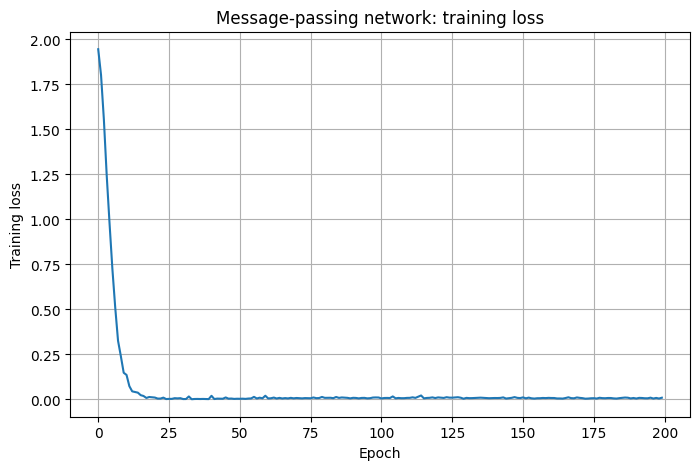

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Message-passing network: training loss")
plt.grid(True)
plt.show()

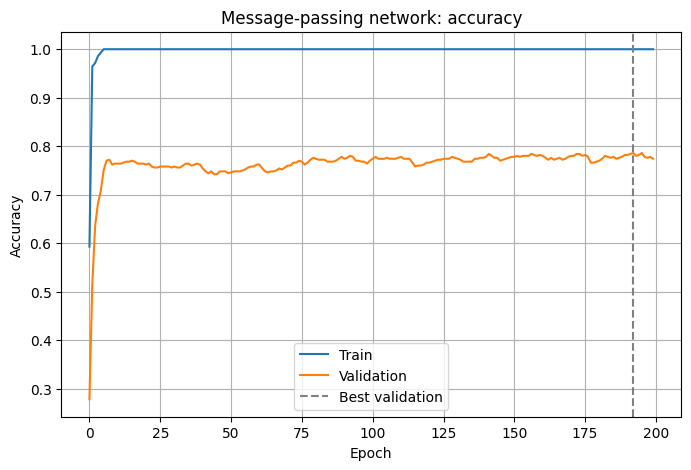

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_acc"], label="Train")
plt.plot(history["val_acc"], label="Validation")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", label="Best validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Message-passing network: accuracy")
plt.legend()
plt.grid(True)
plt.show()

Training accuracy reaches 1.0 quickly: with only 140 labelled nodes, the model can memorise them. Validation accuracy is the number that tells us whether it generalises. Exact curves vary with random initialisation and software versions.

# Part VI — Final test evaluation

## 18. Evaluate the best checkpoint on the test nodes

We load the weights from the best validation epoch and evaluate on the test set **once**.

In [20]:
model.load_state_dict(best_state)

test_acc = accuracy(model, data, data.test_mask)
print(f"Validation accuracy (best checkpoint): {accuracy(model, data, data.val_mask):.4f}")
print(f"Test accuracy:                         {test_acc:.4f}")

Validation accuracy (best checkpoint): 0.7860
Test accuracy:                         0.7950


We now have a complete pipeline with **our own layer**:

$$
\text{Graph}\rightarrow\underbrace{\text{Message}\rightarrow\text{Aggregate}\rightarrow\text{Update}}_{\text{our layer}}\rightarrow\text{Logits}\rightarrow\text{Masked loss}\rightarrow\text{Backpropagation}
$$

The test accuracy is in the same range as the `GCNConv` model from Tutorial 4. That is the point: a short, readable layer we wrote ourselves performs like the library layer.

# Part VII — What happens inside a message-passing network?

## 19. Receptive field

Each message-passing layer lets information travel **one edge farther**:

```text
Layer 0:  node i knows only itself
Layer 1:  node i knows its 1-hop neighbours
Layer 2:  node i knows nodes up to 2 hops away
   ...
Layer K:  node i knows its K-hop neighbourhood
```

This set of nodes is the node's **receptive field**. Our two-layer model sees 2-hop neighbourhoods. Let's measure how large they are in Cora.

In [21]:
from torch_geometric.utils import k_hop_subgraph

node_id = 0
for k in [1, 2, 3, 4]:
    subset, _, _, _ = k_hop_subgraph(node_id, k, data.edge_index, num_nodes=data.num_nodes)
    print(f"{k}-hop receptive field of node {node_id}: {subset.numel()} nodes")

1-hop receptive field of node 0: 4 nodes
2-hop receptive field of node 0: 8 nodes
3-hop receptive field of node 0: 80 nodes
4-hop receptive field of node 0: 205 nodes


The receptive field grows quickly. More layers let a node see more of the graph, but deeper is not automatically better. Repeated averaging makes node representations increasingly similar — a problem called **oversmoothing**.

## 20. GCN is also message passing

We can now write the GCN layer from Tutorials 2–4 in the same three steps:

| Step | GCN (`GCNConv`) | Our layer (`PyGMeanSAGEConv`) |
|---|---|---|
| Message | $\dfrac{1}{\sqrt{\hat d_i\hat d_j}}\,W\mathbf h_j$ | $\mathbf h_j$ |
| Aggregate | sum over $\mathcal N(i)\cup\{i\}$ (self-loop) | mean over $\mathcal N(i)$ |
| Update | result used directly | $W[\mathbf h_i\Vert\mathbf m_i]+\mathbf b$ |

The normalisation $\hat D^{-1/2}\hat A\hat D^{-1/2}$ from Tutorial 2 becomes a **per-edge weight** inside the message, and the self-loop becomes "a node sends a message to itself".

Different GNNs are different choices for these three steps:

$$
\boxed{\text{GNN layer} = \text{Message} + \text{Aggregate} + \text{Update}}
$$

In Tutorial 6, GAT will replace the fixed weight $\frac{1}{\sqrt{\hat d_i\hat d_j}}$ with a **learned** attention weight.

# Part VIII — Inspect predictions

## 21. Compare predicted and true labels on test nodes

In [22]:
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

probabilities = torch.softmax(logits, dim=1)
predictions = logits.argmax(dim=1)
test_ids = data.test_mask.nonzero(as_tuple=False).view(-1)[:15]

print("Node | True | Predicted | Confidence")
print("-------------------------------------")
for i in test_ids.tolist():
    pred = predictions[i].item()
    print(f"{i:4d} | {data.y[i].item():4d} | {pred:9d} | {probabilities[i, pred].item():10.3f}")

Node | True | Predicted | Confidence
-------------------------------------
1708 |    3 |         2 |      0.432
1709 |    2 |         2 |      0.994
1710 |    2 |         2 |      0.906
1711 |    2 |         2 |      1.000
1712 |    2 |         2 |      0.999
1713 |    0 |         5 |      0.419
1714 |    2 |         2 |      0.999
1715 |    2 |         2 |      1.000
1716 |    2 |         2 |      0.989
1717 |    2 |         2 |      0.999
1718 |    2 |         2 |      0.999
1719 |    2 |         2 |      0.999
1720 |    2 |         2 |      0.999
1721 |    2 |         2 |      1.000
1722 |    2 |         2 |      0.997


## 22. Are low-confidence predictions more often wrong?

Softmax scores are not calibrated probabilities, but they still carry information. Let's compare accuracy on confident and less confident test nodes.

In [23]:
test_mask = data.test_mask
confidence = probabilities.max(dim=1).values[test_mask]
correct = (predictions[test_mask] == data.y[test_mask])

threshold = 0.9
high = confidence >= threshold
print(f"Test nodes with confidence >= {threshold}: {int(high.sum())}, accuracy = {correct[high].float().mean():.3f}")
print(f"Test nodes with confidence <  {threshold}: {int((~high).sum())}, accuracy = {correct[~high].float().mean():.3f}")

Test nodes with confidence >= 0.9: 571, accuracy = 0.935
Test nodes with confidence <  0.9: 429, accuracy = 0.608


# 🧪 Hands-on Exercise 4 — Mean vs. sum aggregation

Change `aggr="mean"` to `aggr="add"` in `PyGMeanSAGEConv`, retrain, and compare.

Questions:
1. Does validation accuracy change?
2. Why might sum aggregation be harder to train when degrees vary a lot? (Hint: look at the scale of high-degree nodes.)

In [25]:
# TODO: create a sum-aggregation variant of the layer and retrain.

# class PyGSumSAGEConv(PyGMeanSAGEConv):
#     def __init__(self, in_channels, out_channels):
#         super().__init__(in_channels, out_channels)
#         self.aggr = "add"

# 🧪 Hands-on Exercise 5 — Remove the self features

In the update, we concatenate $\mathbf h_i$ with the neighbour mean. Remove $\mathbf h_i$ and use **only** the neighbour mean (remember to change the linear layer input size to `in_channels`).

Does performance change? What information does the node lose?

In [26]:
# TODO: write a layer that uses only the aggregated neighbour features.

# class NeighborOnlyConv(MessagePassing):
#     def __init__(self, in_channels, out_channels):
#         super().__init__(aggr="mean")
#         self.linear = nn.Linear(in_channels, out_channels)
#
#     def forward(self, x, edge_index):
#         return self.linear(self.propagate(edge_index, x=x))
#
#     def message(self, x_j):
#         return x_j

# 🧪 Hands-on Exercise 6 — Depth and oversmoothing

Build models with 2, 3, 4, and 6 message-passing layers. For each, record the best validation accuracy.

Questions:
1. Does a larger receptive field help on Cora?
2. At what depth does performance start to drop?
3. Connect your answer to the receptive-field sizes from Section 19.

In [27]:
# TODO: build a model with a configurable number of layers.

# class DeepMessagePassingNet(nn.Module):
#     def __init__(self, input_dim, hidden_dim, output_dim, num_layers=3, dropout=0.5):
#         super().__init__()
#         dims = [input_dim] + [hidden_dim] * (num_layers - 1) + [output_dim]
#         self.convs = nn.ModuleList(
#             [PyGMeanSAGEConv(dims[k], dims[k + 1]) for k in range(num_layers)]
#         )
#         self.dropout = dropout
#
#     def forward(self, x, edge_index):
#         for conv in self.convs[:-1]:
#             x = F.relu(conv(x, edge_index))
#             x = F.dropout(x, p=self.dropout, training=self.training)
#         return self.convs[-1](x, edge_index)

# 🧪 Hands-on Exercise 7 — Use `x_i` in the message

Modify `message()` to send the **difference** between the neighbour and the receiving node:

```python
def message(self, x_i, x_j):
    return x_j - x_i
```

Run it on the small example graph first and check one node by hand. Then train it on Cora.

Why might "difference" messages be useful for physical fields such as temperature or pressure?

In [28]:
# TODO: implement a difference-message layer and test it on the small graph.

# class DifferenceConv(MessagePassing):
#     def __init__(self):
#         super().__init__(aggr="mean")
#
#     def forward(self, x, edge_index):
#         return self.propagate(edge_index, x=x)
#
#     def message(self, x_i, x_j):
#         return x_j - x_i
#
# print(DifferenceConv()(x, edge_index))

# Part IX — From citation graphs to computational meshes

## 23. Message passing on a mesh

An unstructured mesh can be represented as a graph: cells (or vertices) become nodes, and shared faces (or mesh edges) become edges.

| Graph concept | Possible mesh interpretation |
|---|---|
| Node | cell centre, mesh vertex, or control volume |
| Edge | cell adjacency or mesh connectivity |
| Node features | pressure, velocity, temperature, turbulence quantities |
| Edge features | relative displacement, distance, face normal, face area |
| Message | learned interaction between neighbouring cells |
| Aggregation | combination of neighbouring contributions |
| Update | new local state of the cell |

The difference message from Exercise 7 is closely related to a discrete gradient or flux, $\mathbf h_j-\mathbf h_i$.

However, a GNN does **not** automatically satisfy conservation laws, boundary conditions, or numerical stability. These must be built in explicitly — for example with antisymmetric messages ($\mathbf m_{j\rightarrow i}=-\mathbf m_{i\rightarrow j}$), edge features from geometry, or finite-volume-inspired message functions. We will return to this in Tutorials 9 and 10.

# 🚀 Final Challenge — Heat diffusion on a graph

Build a message-passing model for a simplified heat-diffusion problem.

1. Create a 2D grid of $n\times n$ points and connect each point to its 4 neighbours (`edge_index`).
2. Generate synthetic data: random initial temperatures $T^0$, then apply a few explicit diffusion steps

$$
T_i^{t+1}=T_i^t+\alpha\sum_{j\in\mathcal N(i)}\left(T_j^t-T_i^t\right)
$$

3. Train a model to predict $T^{t+k}$ from $T^0$ (and optionally the node coordinates).

Compare three models:

| Model | Uses connectivity? | Message | Test MSE |
|---|---|---|---:|
| MLP baseline | ❌ | — | ? |
| Mean message-passing layer | ✅ | $\mathbf h_j$ | ? |
| Difference message-passing layer | ✅ | $\mathbf h_j-\mathbf h_i$ | ? |

Do not focus only on the lowest error. Check whether the predicted field behaves physically: does it smooth out peaks? Is the total heat approximately conserved?

### Completion checklist

- [ ] I can explain message, aggregate, and update.
- [ ] I understand source-to-target edge direction in `edge_index`.
- [ ] I implemented aggregation with `index_add_`.
- [ ] I understand sum, mean, and max aggregation.
- [ ] I implemented a custom PyG `MessagePassing` layer and verified it against my manual code.
- [ ] I trained and evaluated a two-layer message-passing network on Cora.
- [ ] I can describe GCN as a special case of message passing.

# 24. Summary

We learned:
- how a GNN layer splits into message, aggregate, and update
- how `edge_index` direction controls which node receives which message
- how to implement aggregation with `index_add_` without an adjacency matrix
- how to build a trainable GraphSAGE-style layer in plain PyTorch
- how PyG's `MessagePassing`, `propagate()`, `x_i`, and `x_j` work
- how to train our own layer on Cora with the Tutorial 4 workflow
- how receptive fields grow with depth, and why oversmoothing limits depth
- how `GCNConv` fits into the same message-passing framework

The key takeaway:

> Every GNN layer is a choice of **message**, **aggregate**, and **update**. Once you can write these three functions, you can build your own layers.

# 25. What comes next?

## Tutorial 6 — Graph Attention Networks (GAT)

Our layer treats all neighbours equally: the mean gives each one the same weight. GCN uses fixed weights based on node degree. But should every neighbour contribute equally?

In the next tutorial, we let the network **learn** the weights:

```text
message(x_i, x_j)
    ↓
attention score  α_ij = softmax_j( a(x_i, x_j) )
    ↓
weighted aggregation  Σ α_ij · W x_j
```

We will implement attention as a custom `MessagePassing` layer — using exactly the tools from this tutorial.

---

**Learn the graph. Understand the message passing. Build the model. Connect it to the physical world.**